# Лабораторна робота № 4
## Дослідження дерев рішень та ансамблевих методів у задачі багатокласової класифікації за наявності пропущених значень

**Виконала:** Зімірська Юліана, група ФЕІ-42
**Номер у списку групи:** N = 12 → **SEED = 42 + 12 = 54**

**Мета роботи:** дослідити та порівняти дерево рішень (DT), випадковий ліс (RF) і градієнтний бустинг (XGBoost) на датасеті *Annealing* із пропущеними значеннями: вплив способу обробки пропусків, коректний (без витоку) підбір гіперпараметрів Optuna, неупереджене оцінювання (вкладена крос-валідація), статистичне порівняння та інтерпретація моделей (MDI, permutation importance, SHAP).

In [1]:
import warnings, platform
warnings.filterwarnings('ignore', message='IProgress not found')
from io import StringIO
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.datasets import fetch_openml
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_validate, cross_val_score, cross_val_predict)
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
import optuna
import optuna.visualization.matplotlib as ovm
import shap

warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=optuna.exceptions.ExperimentalWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option('display.max_columns', 60, 'display.width', 200)
sns.set_theme(style='whitegrid')

N = 12
SEED = 42 + N            # = 54, єдина константа для всіх джерел випадковості
np.random.seed(SEED)
N_TRIALS = 30       # кількість спроб Optuna на один запуск tune()

MODELS = ['DT', 'RF', 'XGB']
MODEL_NAMES = {'DT': 'Decision Tree', 'RF': 'Random Forest', 'XGB': 'XGBoost'}

# Фіксуємо версії бібліотек (requirements.txt створюється поруч із ноутбуком)
pkgs = ['numpy', 'pandas', 'scipy', 'scikit-learn', 'xgboost', 'optuna', 'shap', 'matplotlib', 'seaborn']
req = '\n'.join(f'{p}=={version(p)}' for p in pkgs)
Path('requirements.txt').write_text(req + '\n')
print('Python', platform.python_version()); print(req)
print('SEED =', SEED)

Python 3.13.16
numpy==2.5.3
pandas==3.0.5
scipy==1.18.1
scikit-learn==1.9.1
xgboost==3.4.1
optuna==5.0.0
shap==0.53.0
matplotlib==3.11.2
seaborn==0.13.2
SEED = 54


## 3.1. Первинний аналіз даних
### 3.1.1–3.1.2. Завантаження, розмір і типи ознак
Датасет завантажується з OpenML (`anneal`, версія 1 — 898 спостережень). Якщо OpenML недоступний (немає мережі), використовується локальна копія того самого ARFF-файлу `anneal.arff` (898 рядків, символ `?` — пропуск), що лежить поруч із ноутбуком.

In [2]:
NUMERIC = ['carbon', 'hardness', 'strength', 'thick', 'width', 'len']

def read_arff_local(path='anneal.arff'):
    lines = Path(path).read_text().splitlines()
    names, start = [], None
    for i, line in enumerate(lines):
        s = line.strip()
        if s.lower().startswith('@attribute'):
            names.append(s.split()[1].strip("'"))
        elif s.lower().startswith('@data'):
            start = i + 1
            break
    body = '\n'.join(l for l in lines[start:] if l.strip() and not l.startswith('%'))
    df = pd.read_csv(StringIO(body), header=None, names=names, quotechar="'",
                     na_values=['?'], keep_default_na=False, dtype=str)
    return df.drop(columns='class'), df['class']

try:
    data = fetch_openml(name='anneal', version=1, as_frame=True)
    X, y = data.data.copy(), data.target.copy()
    SOURCE = 'OpenML anneal v1'
except Exception as e:
    print(f'OpenML недоступний ({type(e).__name__}) — читаю локальну копію anneal.arff')
    X, y = read_arff_local()
    SOURCE = 'anneal.arff (локальна копія, ідентична OpenML anneal v1)'

# числові ознаки -> float, усі інші (категоріальні/бінарні) -> object
for c in X.columns:
    if c in NUMERIC:
        X[c] = pd.to_numeric(X[c]).astype(float)
    else:
        X[c] = X[c].astype(object).where(X[c].notna(), np.nan)
y = y.astype(str)

print('Джерело:', SOURCE)
print('Спостережень:', X.shape[0], '| ознак:', X.shape[1])
print('Числових:', len(X.select_dtypes('number').columns),
      '| категоріальних/бінарних (object):', len(X.select_dtypes(exclude='number').columns))
X.head()

OpenML недоступний (URLError) — читаю локальну копію anneal.arff
Джерело: anneal.arff (локальна копія, ідентична OpenML anneal v1)
Спостережень: 898 | ознак: 38
Числових: 6 | категоріальних/бінарних (object): 32


,family,product-type,steel,carbon,hardness,temper_rolling,condition,formability,strength,non-ageing,surface-finish,surface-quality,enamelability,bc,bf,bt,bw/me,bl,m,chrom,phos,cbond,marvi,exptl,ferro,corr,blue/bright/varn/clean,lustre,jurofm,s,p,shape,thick,width,len,oil,bore,packing
0,NaN,C,A,8.0,0.0,NaN,S,NaN,0.0,NaN,NaN,G,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,COIL,0.700,610.0,0.0,NaN,0,NaN
1,NaN,C,R,0.0,0.0,NaN,S,2,0.0,NaN,NaN,E,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Y,NaN,NaN,NaN,COIL,3.200,610.0,0.0,NaN,0,NaN
2,NaN,C,R,0.0,0.0,NaN,S,2,0.0,NaN,NaN,E,NaN,NaN,Y,NaN,B,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,SHEET,0.700,1300.0,762.0,NaN,0,NaN
3,NaN,C,A,0.0,60.0,T,NaN,NaN,0.0,NaN,NaN,G,NaN,NaN,NaN,NaN,M,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,COIL,2.801,385.1,0.0,NaN,0,NaN
4,NaN,C,A,0.0,60.0,T,NaN,NaN,0.0,NaN,NaN,G,NaN,NaN,NaN,NaN,B,Y,NaN,NaN,NaN,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,SHEET,0.801,255.0,269.0,NaN,0,NaN


In [3]:
# Типи ознак і кількість унікальних значень
info = pd.DataFrame({'dtype': X.dtypes.astype(str),
                     'unique (без NaN)': X.nunique(),
                     'приклад значень': [list(X[c].dropna().unique()[:5]) for c in X.columns]})
info

,dtype,unique (без NaN),приклад значень
family,object,2,"[TN, ZS]"
product-type,object,1,[C]
steel,object,7,"[A, R, K, S, W]"
carbon,float64,10,"[8.0, 0.0, 10.0, 55.0, 70.0]"
hardness,float64,7,"[0.0, 60.0, 45.0, 80.0, 70.0]"
temper_rolling,object,1,[T]
condition,object,2,"[S, A]"
formability,object,4,"[2, 3, 1, 5]"
strength,float64,8,"[0.0, 310.0, 350.0, 500.0, 600.0]"
non-ageing,object,1,[N]


### 3.1.3. Частка пропусків; видалення порожніх і константних ознак

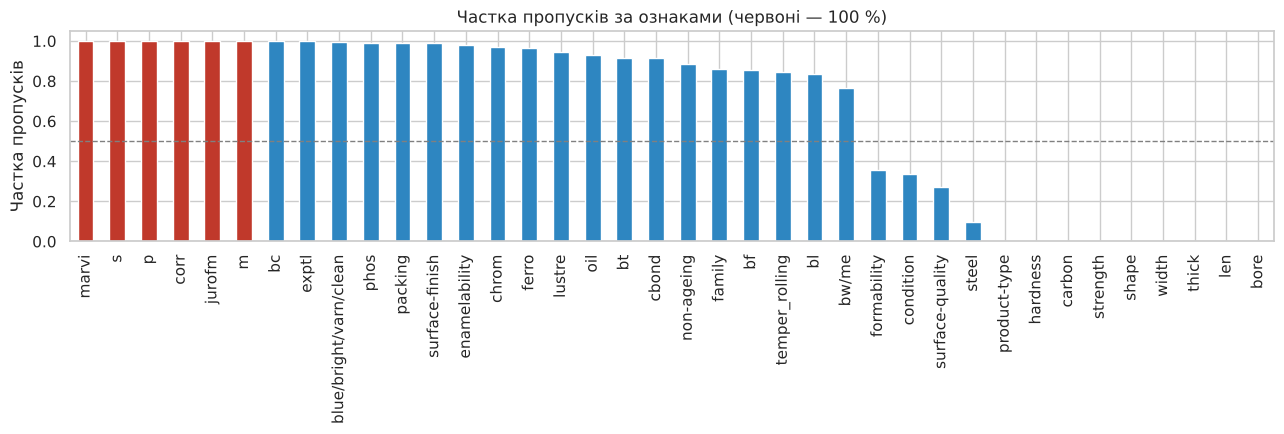

Повністю порожні ознаки: ['m', 'marvi', 'corr', 'jurofm', 's', 'p']
Константні ознаки (одне значення, без пропусків): ['product-type']
Залишилось ознак: 31

Ознаки виду «значення / пропуск» (13): ['temper_rolling', 'non-ageing', 'surface-finish', 'bc', 'bf', 'bt', 'bl', 'chrom', 'phos', 'cbond', 'exptl', 'ferro', 'lustre']


In [4]:
miss = X.isna().mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(13, 4.5))
miss.plot.bar(ax=ax, color=['#c0392b' if v == 1 else '#2e86c1' for v in miss])
ax.set_ylabel('Частка пропусків'); ax.set_title('Частка пропусків за ознаками (червоні — 100 %)')
ax.axhline(0.5, ls='--', c='grey', lw=1)
plt.tight_layout(); plt.show()

empty = [c for c in X.columns if X[c].isna().all()]
constant = [c for c in X.columns if c not in empty and X[c].nunique(dropna=False) <= 1]
print('Повністю порожні ознаки:', empty)
print('Константні ознаки (одне значення, без пропусків):', constant)
X = X.drop(columns=empty + constant)
print('Залишилось ознак:', X.shape[1])

binary_flags = [c for c in X.columns if X[c].dtype == object and X[c].nunique() == 1]
print(f'\nОзнаки виду «значення / пропуск» ({len(binary_flags)}):', binary_flags)

**Коментар.** Видалено 6 повністю порожніх ознак (`m`, `marvi`, `corr`, `jurofm`, `s`, `p`) — вони не містять жодного значення, тож не можуть нести інформації, а `SimpleImputer` взагалі відкидає такі стовпці. Ознака `product-type` має одне значення `C` для всіх 898 об’єктів (без пропусків) — вона константна й нічого не розрізняє. Залишилась 31 ознака.

Більшість решти ознак має дуже високу частку пропусків (19 ознак — понад 75 %). Серед них 13 ознак виду «значення / пропуск» (`bc`, `bf`, `chrom`, `ferro`, `phos`…): у них є лише одне спостережуване значення (`Y`, `C`, `P`, `N`, `T`), а пропуск фактично означає «властивість відсутня / не застосовна». Це **структурні пропуски** (див. `anneal.names`): заповнення модою перетворює таку ознаку на константу, і у варіанті A вся її інформація губиться. Тому для цього датасету індикатори пропусків мають бути особливо корисними.

### 3.1.4. Розподіл цільової змінної

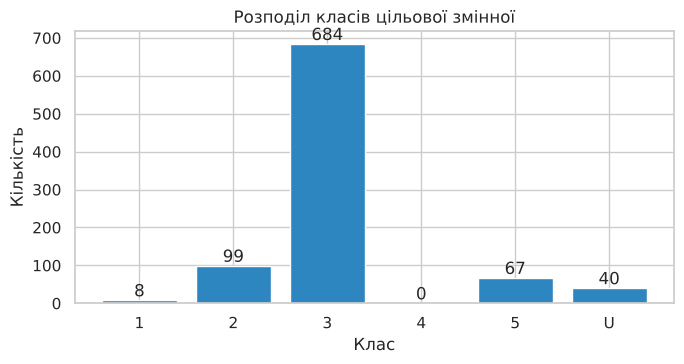

class
1    0.009
2    0.110
3    0.762
4    0.000
5    0.075
U    0.045

Клас 4 описаний у документації, але в даних відсутній.
Найменший клас: 1 (8 спостережень)
Очікувано у train (80 %): ~6.4; у кожному з 5 зовнішніх блоків nested CV: ~5.1 у тренувальній частині; у внутрішніх 3 блоках: ~3.4 у тренувальній частині.


In [5]:
counts = y.value_counts().reindex(['1', '2', '3', '4', '5', 'U'], fill_value=0)
fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.bar(counts.index, counts.values, color='#2e86c1')
ax.bar_label(bars)
ax.set_xlabel('Клас'); ax.set_ylabel('Кількість'); ax.set_title('Розподіл класів цільової змінної')
plt.tight_layout(); plt.show()
print((counts / counts.sum()).round(3).to_string())
print('\nКлас 4 описаний у документації, але в даних відсутній.')
min_cls = counts[counts > 0].idxmin()
n_min = counts[min_cls]
print(f'Найменший клас: {min_cls} ({n_min} спостережень)')
print(f'Очікувано у train (80 %): ~{n_min*0.8:.1f}; у кожному з 5 зовнішніх блоків nested CV: ~{n_min*0.8*0.8:.1f} '
      f'у тренувальній частині; у внутрішніх 3 блоках: ~{n_min*0.8*0.8*2/3:.1f} у тренувальній частині.')

**Коментар і рішення щодо рідкісних класів.** Клас `3` домінує (76,2 %), найменший клас `1` має лише 8 об’єктів (0,9 %), клас `4` у даних відсутній. Клас `1` **залишено**: це реальний клас процесу, об’єднання з іншим класом спотворило б задачу, а виключення прибрало б саме той випадок, де дисбаланс найважливіший. LabelEncoder кодує лише наявні 5 класів (`1, 2, 3, 5, U` → `0…4`), тому відсутній клас `4` проблем не створює.

Вплив на крос-валідацію: у тренувальній вибірці буде 6 об’єктів класу `1`, у тесті — 2. У 5-блочній CV кожен валідаційний блок містить лише 1–2 об’єкти класу `1`, тож одна помилка на ньому знижує recall цього класу до 0–0,5 і macro F1 блоку приблизно на 0,1–0,2. Це головне джерело великого стандартного відхилення macro F1. У вкладеній CV внутрішній поділ має 3 блоки, щоб у кожному внутрішньому тренувальному блоці було щонайменше 2–3 об’єкти класу `1` (перевірено в п. 3.4).

### 3.1.5. Аналіз механізму пропусків
Для кожної ознаки з пропусками будуємо таблицю спряженості «пропуск / не пропуск» × клас і перевіряємо незалежність критерієм χ². Оскільки частоти в таблицях дуже малі (ознаки з ~99 % пропусків, класи з 8 об’єктів), асимптотичний χ² ненадійний; точний критерій Фішера в `scipy` реалізований лише для 2×2, тому для таблиць 2×5 додатково обчислюємо **точне перестановкове (Монте-Карло) p-значення** χ²-статистики — це узагальнення ідеї точного тесту Фішера на r×c-таблиці. Силу зв’язку оцінюємо V Крамера.

In [6]:
def chi2_perm_test(is_missing, target, n_perm=10000, rng=None):
    rng = np.random.default_rng(rng)
    tab = pd.crosstab(is_missing, target)
    chi2, p_asym, dof, _ = stats.chi2_contingency(tab, correction=False)
    codes = pd.factorize(target)[0]; m = is_missing.to_numpy().astype(int); k = codes.max() + 1
    def stat(c):
        t = np.zeros((2, k)); np.add.at(t, (m, c), 1)
        t = t[:, t.sum(0) > 0]
        e = t.sum(1, keepdims=True) * t.sum(0, keepdims=True) / t.sum()
        return ((t - e) ** 2 / e).sum()
    obs = stat(codes)
    perm = np.array([stat(rng.permutation(codes)) for _ in range(n_perm)])
    p_perm = (np.sum(perm >= obs - 1e-12) + 1) / (n_perm + 1)
    v = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
    return chi2, p_asym, p_perm, v

with_missing = X.columns[X.isna().any()]
rows = []
for c in with_missing:
    chi2, p_a, p_p, v = chi2_perm_test(X[c].isna(), y, n_perm=5000, rng=SEED)
    rows.append({'ознака': c, 'частка пропусків': X[c].isna().mean(), 'χ²': chi2,
                 'p (асимпт.)': p_a, 'p (перестановк.)': p_p, 'V Крамера': v})
mech = pd.DataFrame(rows).sort_values('частка пропусків', ascending=False).reset_index(drop=True)
mech['пов’язано з класом (α=0.05)'] = np.where(mech['p (перестановк.)'] < 0.05, 'так', 'ні')
mech.round(4)

,ознака,частка пропусків,χ²,p (асимпт.),p (перестановк.),V Крамера,пов’язано з класом (α=0.05)
0,bc,0.9989,0.3132,0.9889,1.0000,0.0187,ні
1,exptl,0.9978,222.9967,0.0000,0.0002,0.4983,так
2,blue/bright/varn/clean,0.9933,37.3654,0.0000,0.0012,0.2040,так
3,phos,0.9922,87.5030,0.0000,0.0002,0.3122,так
4,surface-finish,0.9900,73.3717,0.0000,0.0002,0.2858,так
5,packing,0.9900,2.8443,0.5842,0.4355,0.0563,ні
6,enamelability,0.9822,44.4376,0.0000,0.0002,0.2225,так
7,chrom,0.9710,332.0928,0.0000,0.0002,0.6081,так
8,ferro,0.9666,384.9498,0.0000,0.0002,0.6547,так
9,lustre,0.9432,13.0113,0.0112,0.0170,0.1204,так


In [7]:
# Детально: таблиці спряженості для 5 ознак із найбільшою часткою пропусків
top5_miss = mech['ознака'].head(5).tolist()
for c in top5_miss:
    tab = pd.crosstab(X[c].isna().map({True: 'пропуск', False: 'не пропуск'}), y)
    r = mech.set_index('ознака').loc[c]
    print(f'--- {c}: χ²={r["χ²"]:.2f}, p_перест.={r["p (перестановк.)"]:.4f}, V={r["V Крамера"]:.3f}')
    print(tab.to_string(), '\n')

--- bc: χ²=0.31, p_перест.=1.0000, V=0.019
class       1   2    3   5   U
bc                            
не пропуск  0   0    1   0   0
пропуск     8  99  683  67  40 

--- exptl: χ²=223.00, p_перест.=0.0002, V=0.498
class       1   2    3   5   U
exptl                         
не пропуск  2   0    0   0   0
пропуск     6  99  684  67  40 

--- blue/bright/varn/clean: χ²=37.37, p_перест.=0.0012, V=0.204
class                   1   2    3   5   U
blue/bright/varn/clean                    
не пропуск              1   4    1   0   0
пропуск                 7  95  683  67  40 

--- phos: χ²=87.50, p_перест.=0.0002, V=0.312
class       1   2    3   5   U
phos                          
не пропуск  0   0    0   7   0
пропуск     8  99  684  60  40 

--- surface-finish: χ²=73.37, p_перест.=0.0002, V=0.286
class           1   2    3   5   U
surface-finish                    
не пропуск      0   9    0   0   0
пропуск         8  90  684  67  40 



**Висновок щодо механізму пропусків.** Для 21 з 23 ознак із пропусками факт пропуску статистично значущо пов’язаний із класом (перестановкове p < 0,05). Винятки — `bc` (заповнений лише в одному об’єкті, тест не має потужності) та `packing`. Найсильніший зв’язок (V Крамера): `surface-quality` (0,74), `family` (0,72), `ferro` (0,65), `chrom` (0,61), `non-ageing` (0,54), `temper_rolling` (0,50). Серед 5 ознак із найбільшою часткою пропусків видно дуже характерну картину: `exptl` заповнена лише в об’єктах класу `1`, `phos` — лише в класі `5`, `surface-finish` — лише в класі `2`.

Отже, пропуски **не схожі на MCAR**: імовірність пропуску залежить від класу (і, через структурність, від типу продукції). За даними неможливо остаточно розрізнити MAR і MNAR, але для прогнозу це не головне — важливо, що сам факт пропуску несе інформацію про ціль. Гіпотеза: індикатори пропусків (варіант B) мають помітно покращити якість.

### 3.1.6. Кодування цільової змінної

In [8]:
le = LabelEncoder()
y_enc = le.fit_transform(y)
CLASS_NAMES = [str(c) for c in le.classes_]
print(dict(zip(CLASS_NAMES, range(len(CLASS_NAMES)))))

{'1': 0, '2': 1, '3': 2, '5': 3, 'U': 4}


## 3.2. Поділ даних і пайплайн обробки
Стратифікований поділ 80/20. Тестова вибірка використовується **один раз** — у п. 3.6.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.2, stratify=y_enc, random_state=SEED)
print('train:', X_train.shape, '| test:', X_test.shape)
pd.DataFrame({'train': pd.Series(y_train).map(dict(enumerate(CLASS_NAMES))).value_counts(),
              'test': pd.Series(y_test).map(dict(enumerate(CLASS_NAMES))).value_counts()}).loc[CLASS_NAMES]

train: (718, 31) | test: (180, 31)


,train,test
1,6,2
2,79,20
3,547,137
5,54,13
U,32,8


**Варіант A** — медіана для числових, мода + one-hot для категоріальних.
**Варіант B** — те саме + бінарні індикатори пропусків (`MissingIndicator`) для кожної ознаки, що мала пропуски в тренувальних даних.

Уся обробка знаходиться всередині `Pipeline`, тому імпутер і кодувальник навчаються лише на тренувальній частині кожного блоку — витоку немає.

Одне відхилення від шаблону: у `MissingIndicator` встановлено `error_on_new=False`. Інакше, якщо у валідаційному блоці трапиться пропуск в ознаці, яка в тренувальному блоці пропусків не мала (а в цьому датасеті таких «майже повних» ознак кілька), `transform` завершився б помилкою. З `False` така ознака просто не отримує індикатора — це відповідає логіці `features='missing-only'`.

In [10]:
def make_model(name, params=None):
    params = params or {}
    if name == 'DT':
        return DecisionTreeClassifier(random_state=SEED, **params)
    if name == 'RF':
        return RandomForestClassifier(random_state=SEED, n_jobs=-1, **params)
    return XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric='mlogloss', **params)

def build_preprocessor(with_indicators: bool) -> ColumnTransformer:
    transformers = [
        ('num', SimpleImputer(strategy='median'), make_column_selector(dtype_include='number')),
        ('cat', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), make_column_selector(dtype_exclude='number')),
    ]
    if with_indicators:
        transformers.append(('miss', MissingIndicator(features='missing-only', error_on_new=False),
                             make_column_selector()))
    return ColumnTransformer(transformers)

def build_pipeline(name, with_indicators=True, params=None):
    return Pipeline([('prep', build_preprocessor(with_indicators)),
                     ('clf', make_model(name, params))])

for wi in (False, True):
    p = build_preprocessor(wi).fit(X_train)
    print(f'Варіант {"B" if wi else "A"}: {len(p.get_feature_names_out())} ознак після обробки')

Варіант A: 53 ознак після обробки
Варіант B: 76 ознак після обробки


## 3.3. Базові моделі (типові гіперпараметри)
Повторна стратифікована крос-валідація 5 блоків × 3 повторення на тренувальній вибірці; **один і той самий об’єкт `cv`** для всіх моделей і варіантів (потрібно для парного тесту в п. 3.5).

In [11]:
scoring = {'acc': 'accuracy', 'f1m': 'f1_macro', 'bacc': 'balanced_accuracy'}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

cv_res = {}   # (variant, model) -> dict of arrays
for variant, wi in (('A', False), ('B', True)):
    for m in MODELS:
        r = cross_validate(build_pipeline(m, with_indicators=wi), X_train, y_train, cv=cv, scoring=scoring)
        cv_res[(variant, m)] = {k: r[f'test_{k}'] for k in scoring}

def pm(a): return f'{np.mean(a):.4f} ± {np.std(a, ddof=1):.4f}'
def cv_table(variant):
    return pd.DataFrame({MODEL_NAMES[m]: {'Accuracy': pm(cv_res[(variant, m)]['acc']),
                                          'Macro F1': pm(cv_res[(variant, m)]['f1m']),
                                          'Balanced acc.': pm(cv_res[(variant, m)]['bacc'])}
                         for m in MODELS}).T

**Таблиця 1.** Крос-валідація (5×3), варіант A, типові параметри

In [12]:
cv_table('A')

,Accuracy,Macro F1,Balanced acc.
Decision Tree,0.9471 ± 0.0134,0.8786 ± 0.0856,0.8825 ± 0.0902
Random Forest,0.9531 ± 0.0136,0.9222 ± 0.0508,0.9238 ± 0.0578
XGBoost,0.9536 ± 0.0126,0.8940 ± 0.0778,0.8851 ± 0.0812


**Таблиця 2.** Крос-валідація (5×3), варіант B, типові параметри

In [13]:
cv_table('B')

,Accuracy,Macro F1,Balanced acc.
Decision Tree,0.9875 ± 0.0096,0.9592 ± 0.0541,0.9556 ± 0.0577
Random Forest,0.9921 ± 0.0074,0.9672 ± 0.0527,0.9639 ± 0.0568
XGBoost,0.9879 ± 0.0089,0.9635 ± 0.0539,0.9603 ± 0.0573


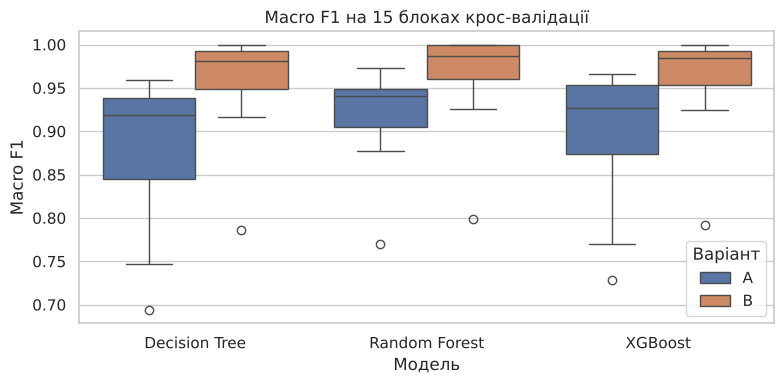

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
plot_df = pd.DataFrame([{'Модель': MODEL_NAMES[m], 'Варіант': v, 'Macro F1': s}
                        for (v, m), r in cv_res.items() for s in r['f1m']])
sns.boxplot(data=plot_df, x='Модель', y='Macro F1', hue='Варіант', ax=ax)
ax.set_title('Macro F1 на 15 блоках крос-валідації')
plt.tight_layout(); plt.show()

**Коментар.** Варіант B покращив усі три моделі за всіма метриками: macro F1 DT 0,879 → 0,959, RF 0,922 → 0,967, XGB 0,894 → 0,964; accuracy зросла з ~0,95 до ~0,99. Причина — структурні пропуски: у варіанті A 13 ознак «значення / пропуск» після імпутації модою стають константами, а у варіанті B їхня інформація повертається через індикатори (76 ознак після обробки проти 53).

Ефект стелі добре видно: accuracy всіх моделей у варіанті B відрізняється в третьому знаку, а стандартне відхилення macro F1 (≈0,05) у кілька разів більше за різниці між моделями (≈0,004–0,008). Великий розкид macro F1 при малому розкиді accuracy пояснюється класом `1` (1–2 об’єкти у валідаційному блоці). Тому без статистичного тесту (п. 3.5) робити висновок «RF найкращий» не можна.

## 3.4. Підбір гіперпараметрів (Optuna), варіант B
У цільову функцію передається **весь пайплайн** (обробка + модель) і сирі `X`, тому імпутер у кожному внутрішньому блоці бачить лише свою тренувальну частину. Внутрішня CV — 3 блоки (через найменший клас).

In [15]:
def suggest_params(trial, name):
    if name == 'DT':
        return {
            'max_depth': trial.suggest_int('max_depth', 2, 20),
            'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
            'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced']),
        }
    if name == 'RF':
        return {
            'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
            'max_depth': trial.suggest_int('max_depth', 3, 30),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
            'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', 0.5]),
            'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced', 'balanced_subsample']),
        }
    return {  # XGB
        'n_estimators': trial.suggest_int('n_estimators', 50, 400),
        'max_depth': trial.suggest_int('max_depth', 2, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'min_child_weight': trial.suggest_float('min_child_weight', 1, 10, log=True),
    }

def tune(name, X_tr, y_tr, n_trials=N_TRIALS):
    inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
    def objective(trial):
        pipe = build_pipeline(name, True, suggest_params(trial, name))
        return cross_val_score(pipe, X_tr, y_tr, cv=inner, scoring='f1_macro').mean()
    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=n_trials)
    return study

# Перевірка мінімальної кількості об'єктів найменшого класу на кожному рівні
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
inner_chk = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
mins = []
for tr_idx, va_idx in outer.split(X_train, y_train):
    ytr = y_train[tr_idx]
    inner_min = min(np.bincount(ytr[i_tr], minlength=len(CLASS_NAMES)).min()
                    for i_tr, _ in inner_chk.split(X_train.iloc[tr_idx], ytr))
    mins.append({'outer train': np.bincount(ytr, minlength=len(CLASS_NAMES)).min(),
                 'outer val': np.bincount(y_train[va_idx], minlength=len(CLASS_NAMES)).min(),
                 'inner train (min)': inner_min})
print('Мінімальна кількість об’єктів класу в блоках:')
pd.DataFrame(mins, index=[f'outer {i+1}' for i in range(5)])

Мінімальна кількість об’єктів класу в блоках:


,outer train,outer val,inner train (min)
outer 1,5,1,3
outer 2,5,1,3
outer 3,4,2,2
outer 4,5,1,3
outer 5,5,1,3


### Вкладена крос-валідація (5 зовнішніх × 3 внутрішніх блоки)
На кожному зовнішньому блоці `tune()` запускається **лише на його тренувальній частині**, якість рахується на валідаційній. Це займає найбільше часу в ноутбуці.

In [16]:
%%time
nested = {}
for m in MODELS:
    scores = []
    for tr_idx, va_idx in outer.split(X_train, y_train):
        X_tr, y_tr = X_train.iloc[tr_idx], y_train[tr_idx]
        X_va, y_va = X_train.iloc[va_idx], y_train[va_idx]
        study = tune(m, X_tr, y_tr)
        model = build_pipeline(m, True, study.best_params).fit(X_tr, y_tr)
        scores.append(f1_score(y_va, model.predict(X_va), average='macro'))
    nested[m] = np.array(scores)
    print(f'{MODEL_NAMES[m]:14s} nested macro F1 по блоках: {np.round(scores, 4)}')

Decision Tree  nested macro F1 по блоках: [0.9809 0.7917 0.833  0.9324 1.    ]


Random Forest  nested macro F1 по блоках: [0.9837 0.7705 0.9228 1.     0.9324]


XGBoost        nested macro F1 по блоках: [1.     0.7991 0.9638 1.     0.9926]
CPU times: user 12min 10s, sys: 1min 32s, total: 13min 43s
Wall time: 11min 52s


### Фінальна оптимізація на всій тренувальній вибірці

In [17]:
%%time
studies, final_models = {}, {}
for m in MODELS:
    studies[m] = tune(m, X_train, y_train)
    final_models[m] = build_pipeline(m, True, studies[m].best_params).fit(X_train, y_train)

import joblib
Path('models').mkdir(exist_ok=True)
for m, mdl in final_models.items():
    joblib.dump(mdl, f'models/final_{m}.joblib')
print('Моделі збережено в ./models/')

Моделі збережено в ./models/
CPU times: user 2min 12s, sys: 13.4 s, total: 2min 25s
Wall time: 1min 55s


**Таблиця 3.** Вкладена крос-валідація (варіант B, після оптимізації) та `best_value` звичайної оптимізації на всій тренувальній вибірці

In [18]:
# Для чесного порівняння «до/після оптимізації»: типові параметри на ТИХ САМИХ 5 зовнішніх блоках
default_outer = {m: cross_val_score(build_pipeline(m, True), X_train, y_train, cv=outer, scoring='f1_macro')
                 for m in MODELS}
t3 = pd.DataFrame({MODEL_NAMES[m]: {
        'Nested CV macro F1 (mean ± std)': pm(nested[m]),
        'best_value (вся train-вибірка)': f'{studies[m].best_value:.4f}',
        'Різниця best_value − nested': f'{studies[m].best_value - nested[m].mean():+.4f}',
        'Типові параметри, ті самі 5 блоків (B)': pm(default_outer[m]),
        'Приріст від оптимізації (nested − типові)': f'{nested[m].mean() - default_outer[m].mean():+.4f}',
        'Типові параметри, CV 5×3 (B)': pm(cv_res[("B", m)]["f1m"]),
    } for m in MODELS}).T
t3

,Nested CV macro F1 (mean ± std),best_value (вся train-вибірка),Різниця best_value − nested,"Типові параметри, ті самі 5 блоків (B)",Приріст від оптимізації (nested − типові),"Типові параметри, CV 5×3 (B)"
Decision Tree,0.9076 ± 0.0915,0.9451,+0.0375,0.9402 ± 0.0871,-0.0326,0.9592 ± 0.0541
Random Forest,0.9219 ± 0.0908,0.9639,+0.0420,0.9538 ± 0.0875,-0.0319,0.9672 ± 0.0527
XGBoost,0.9511 ± 0.0863,0.9400,-0.0111,0.9481 ± 0.0886,+0.0030,0.9635 ± 0.0539


**Коментар.** `best_value` (найкраще середнє внутрішньої 3-блочної CV на всій train-вибірці) перевищує неупереджену оцінку вкладеної CV для DT на +0,038 і для RF на +0,042 — це і є оптимістичне зміщення: ми обираємо максимум із 30 зашумлених оцінок, і в нього «вбудований» сприятливий шум конкретних блоків. Якби подати `best_value` як якість, DT і RF були б переоцінені приблизно на 4 процентні пункти. Для XGBoost різниця від’ємна (−0,011), але вона значно менша за стандартне відхилення nested-оцінки (≈0,09) — це шум, а не відсутність зміщення: обидві величини оцінюють трохи різні речі (3-блочна CV на 718 об’єктах проти 5 моделей, навчених на 574 об’єктах).

Розкид вкладеної CV великий (≈0,09) і для всіх моделей визначається одним блоком (блок 2: macro F1 ≈ 0,77–0,80) — саме в ньому помилки на 1–2 об’єктах класу `1`.

Порівняння з типовими параметрами **на тих самих 5 зовнішніх блоках** показує, що оптимізація майже нічого не дала: для DT і RF nested-оцінка навіть нижча (−0,033 і −0,032), для XGBoost — мінімальний приріст +0,003. Типові параметри (повністю виросле дерево, `min_samples_leaf = 1`) уже дозволяють виділяти листки для рідкісних класів, а внутрішня CV з 2–3 об’єктами класу `1` у тренувальних блоках дає дуже шумну цільову функцію, під шум якої Optuna частково й підлаштовується.

**Таблиця 4.** Найкращі гіперпараметри, знайдені Optuna (оптимізація на всій тренувальній вибірці)

In [19]:
t4 = pd.DataFrame({MODEL_NAMES[m]: {k: (round(v, 4) if isinstance(v, float) else v)
                                    for k, v in studies[m].best_params.items()} for m in MODELS})
t4.fillna('—')

,Decision Tree,Random Forest,XGBoost
max_depth,8.0,13,9.0
min_samples_split,4.0,—,—
min_samples_leaf,1.0,1,—
class_weight,—,—,—
n_estimators,—,250,355.0
max_features,—,sqrt,—
learning_rate,—,—,0.0425
subsample,—,—,0.867
colsample_bytree,—,—,0.616
min_child_weight,—,—,1.0765


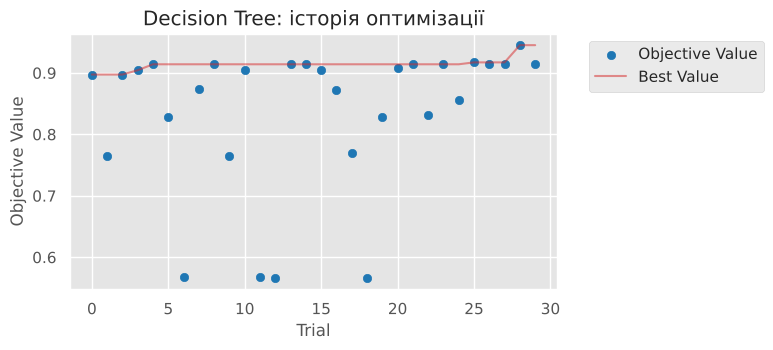

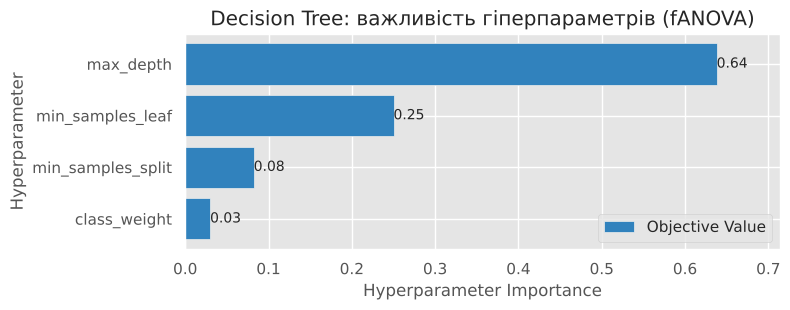

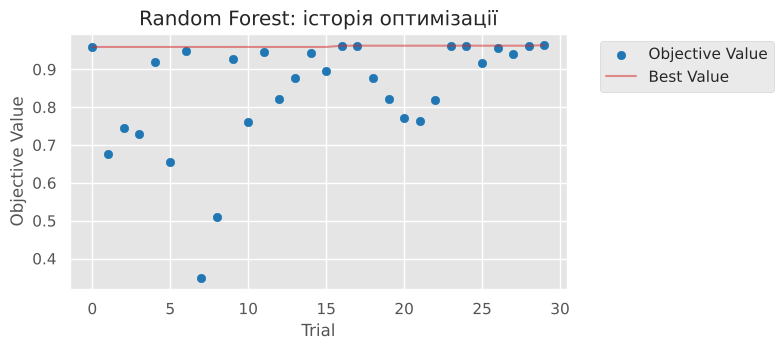

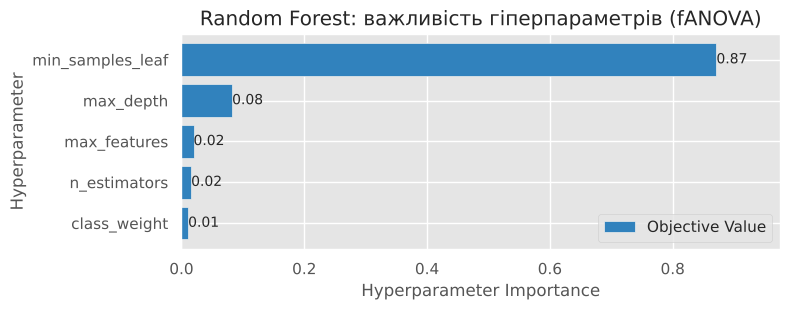

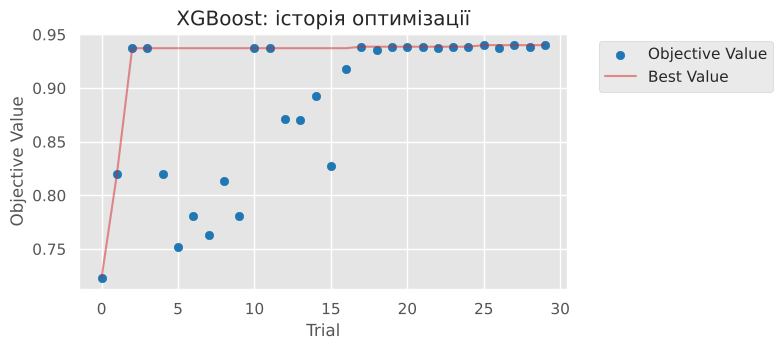

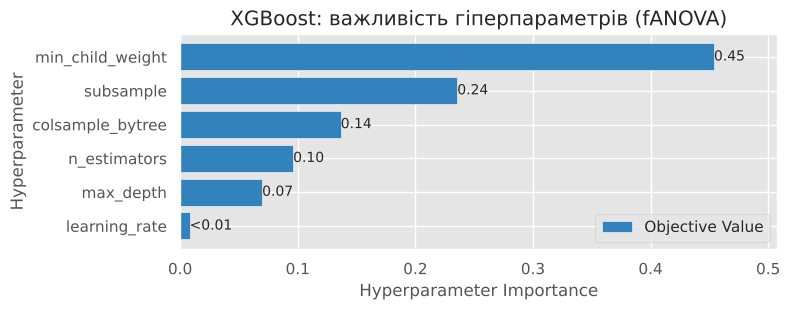

In [20]:
for m in MODELS:
    ax = ovm.plot_optimization_history(studies[m])
    ax.figure.set_size_inches(8, 3.6); ax.set_title('', loc='left'); ax.set_title(f'{MODEL_NAMES[m]}: історія оптимізації')
    plt.tight_layout(); plt.show()
    ax = ovm.plot_param_importances(studies[m], evaluator=optuna.importance.FanovaImportanceEvaluator(seed=SEED))
    ax.figure.set_size_inches(8, 3.2); ax.set_title('', loc='left'); ax.set_title(f'{MODEL_NAMES[m]}: важливість гіперпараметрів (fANOVA)')
    plt.tight_layout(); plt.show()

**Коментар до графіків Optuna.**
- **Decision Tree:** значення цільової функції швидко виходять на плато ≈0,91, а останнє покращення найкращого значення (до 0,945) — лише на спробі № 28 (нумерація з 0), тобто за 30 спроб оптимізація ще не повністю збіглася. Найважливіший гіперпараметр — `max_depth` (0,64), далі `min_samples_leaf` (0,25); надто мілкі дерева (глибина 2–3) не встигають виділити рідкісні класи — звідси провали до ≈0,57.
- **Random Forest:** вже перша спроба дає ≈0,96, далі лише незначні покращення — плато досягнуто рано, оптимізація збіглася. Переважає `min_samples_leaf` (0,87): спроби з великим мінімальним листком (до 10) падають до 0,35–0,7, бо клас `1` (2–3 об’єкти у внутрішньому тренувальному блоці) фізично не може утворити власний листок. `n_estimators`, `max_features` і `class_weight` майже не впливають.
- **XGBoost:** найкраще значення ≈0,94 досягнуто вже на 3-й спробі, а з 16-ї спроби TPE стабільно пропонує конфігурації поблизу оптимуму — оптимізація збіглася. Найважливіший `min_child_weight` (0,45) — аналог мінімального розміру листка, далі `subsample` (0,24) і `colsample_bytree` (0,14); `learning_rate` в обраному діапазоні майже не впливає.

Спільний висновок: у всіх трьох моделях вирішальними є параметри, що обмежують мінімальний розмір листка, — вони визначають, чи може модель виділити окремі листки для найрідкісніших класів.

## 3.5. Статистичне порівняння (скоригований t-тест Наде–Бенжіо)
$$t = \frac{\bar d}{\sqrt{\hat\sigma_d^2\left(\frac{1}{kr} + \frac{n_{test}}{n_{train}}\right)}},\qquad df = kr-1$$
Використовуються результати п. 3.3 (однакові 15 блоків для всіх моделей).

In [21]:
def corrected_ttest(a, b, n_train, n_test):
    d = np.asarray(a) - np.asarray(b)
    J = len(d)                                   # J = k * r
    d_bar, var = d.mean(), d.var(ddof=1)
    if var == 0:
        return d_bar, np.nan, 1.0
    t = d_bar / np.sqrt(var * (1 / J + n_test / n_train))
    p = 2 * stats.t.sf(abs(t), df=J - 1)
    return d_bar, t, p

n_test_fold = len(X_train) / 5
n_train_fold = len(X_train) - n_test_fold

rows = []
for m in MODELS:
    d, t, p = corrected_ttest(cv_res[('B', m)]['f1m'], cv_res[('A', m)]['f1m'], n_train_fold, n_test_fold)
    rows.append({'Порівняння': f'{MODEL_NAMES[m]}: B − A', 'd̄': d, 't': t, 'p': p})

rank_B = sorted(MODELS, key=lambda m: cv_res[('B', m)]['f1m'].mean(), reverse=True)
best1, best2 = rank_B[:2]
d, t, p = corrected_ttest(cv_res[('B', best1)]['f1m'], cv_res[('B', best2)]['f1m'], n_train_fold, n_test_fold)
rows.append({'Порівняння': f'B: {MODEL_NAMES[best1]} − {MODEL_NAMES[best2]}', 'd̄': d, 't': t, 'p': p})

t5 = pd.DataFrame(rows)
t5['Висновок (α = 0.05)'] = np.where(t5['p'] < 0.05, 'різниця значуща', 'різниця незначуща')
t5.round(4)

,Порівняння,d̄,t,p,Висновок (α = 0.05)
0,Decision Tree: B − A,0.0806,2.0071,0.0644,різниця незначуща
1,Random Forest: B − A,0.0449,4.1426,0.0010,різниця значуща
2,XGBoost: B − A,0.0695,1.7919,0.0948,різниця незначуща
3,B: Random Forest − XGBoost,0.0037,0.9364,0.3650,різниця незначуща


In [22]:
# Для порівняння: що дав би звичайний парний t-тест (некоректний — занижує дисперсію)
for m in MODELS:
    tt = stats.ttest_rel(cv_res[('B', m)]['f1m'], cv_res[('A', m)]['f1m'])
    print(f'{MODEL_NAMES[m]:14s} звичайний парний t-тест B−A: p = {tt.pvalue:.4f}')
tt = stats.ttest_rel(cv_res[('B', best1)]['f1m'], cv_res[('B', best2)]['f1m'])
print(f'{MODEL_NAMES[best1]} − {MODEL_NAMES[best2]} (B): p = {tt.pvalue:.4f}')

Decision Tree  звичайний парний t-тест B−A: p = 0.0006
Random Forest  звичайний парний t-тест B−A: p = 0.0000
XGBoost        звичайний парний t-тест B−A: p = 0.0016
Random Forest − XGBoost (B): p = 0.0606


**Таблиця 5** — наведена вище.

**Коментар.** За скоригованим тестом Наде–Бенжіо значущим є лише покращення від індикаторів пропусків для **Random Forest** (d̄ = +0,045, p = 0,001). Для DT (d̄ = +0,081, p = 0,064) і XGBoost (d̄ = +0,070, p = 0,095) середній приріст навіть більший, але й розкид різниць по блоках більший, тому на рівні α = 0,05 різниця незначуща — хоча напрям ефекту однаковий в усіх моделях. Різниця між двома найкращими моделями варіанту B (RF − XGB, d̄ = +0,004, p = 0,365) незначуща: перевагу RF у табл. 2 не можна відрізнити від шуму.

Для порівняння, звичайний парний t-тест дав би p < 0,002 для всіх трьох порівнянь A/B — він ігнорує перетин тренувальних множин блоків і занижує дисперсію, тобто «знаходить» значущість, якої скоригований тест не підтверджує.

## 3.6. Фінальна оцінка на тестовій вибірці

In [23]:
test_pred = {m: final_models[m].predict(X_test) for m in MODELS}
t6 = pd.DataFrame({MODEL_NAMES[m]: {'Accuracy': accuracy_score(y_test, test_pred[m]),
                                    'Macro F1': f1_score(y_test, test_pred[m], average='macro'),
                                    'Balanced acc.': balanced_accuracy_score(y_test, test_pred[m]),
                                    'Nested CV macro F1': nested[m].mean()}
                   for m in MODELS}).T
t6.round(4)

,Accuracy,Macro F1,Balanced acc.,Nested CV macro F1
Decision Tree,1.0000,1.0000,1.0000,0.9076
Random Forest,0.9889,0.9803,0.9735,0.9219
XGBoost,0.9833,0.9129,0.8735,0.9511


**Таблиця 6** — якість фінальних моделей на тестовій вибірці (останній стовпець — для порівняння з CV).

In [24]:
BEST = max(MODELS, key=lambda m: nested[m].mean())   # найкраща — за неупередженою оцінкою (nested CV)
print('Найкраща модель за nested CV:', MODEL_NAMES[BEST])
print('Кількість об’єктів класів у тесті:', dict(zip(CLASS_NAMES, np.bincount(y_test, minlength=len(CLASS_NAMES)))))
print()
print(classification_report(y_test, test_pred[BEST], target_names=CLASS_NAMES, digits=4, zero_division=0))

Найкраща модель за nested CV: XGBoost
Кількість об’єктів класів у тесті: {'1': np.int64(2), '2': np.int64(20), '3': np.int64(137), '5': np.int64(13), 'U': np.int64(8)}



              precision    recall  f1-score   support

           1     1.0000    0.5000    0.6667         2
           2     0.9524    1.0000    0.9756        20
           3     0.9855    0.9927    0.9891       137
           5     1.0000    1.0000    1.0000        13
           U     1.0000    0.8750    0.9333         8

    accuracy                         0.9833       180
   macro avg     0.9876    0.8735    0.9129       180
weighted avg     0.9837    0.9833    0.9823       180



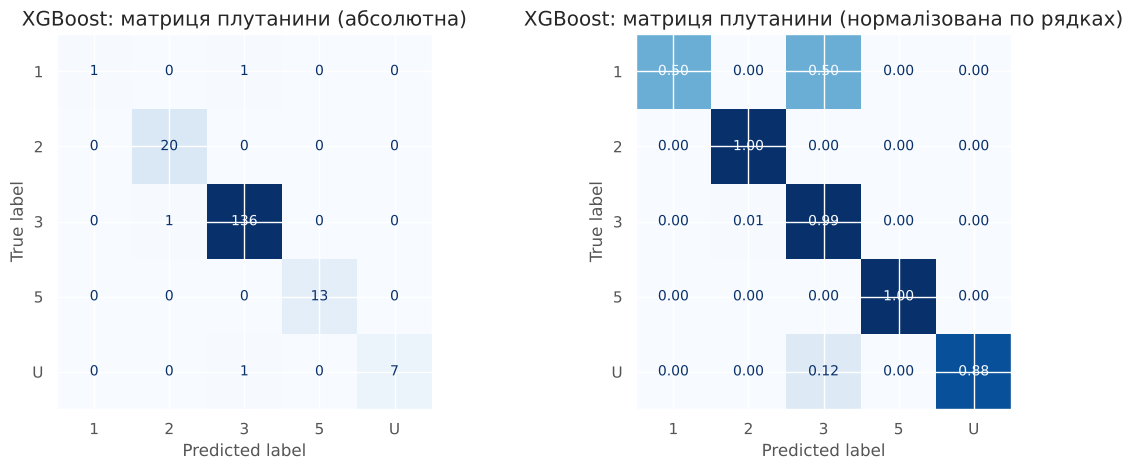

,модель,справжній,прогноз,к-сть
0,Random Forest,3,2,1
1,Random Forest,U,3,1
2,XGBoost,1,3,1
3,XGBoost,3,2,1
4,XGBoost,U,3,1


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, norm, title in [(axes[0], None, 'абсолютна'), (axes[1], 'true', 'нормалізована по рядках')]:
    cm = confusion_matrix(y_test, test_pred[BEST], normalize=norm, labels=range(len(CLASS_NAMES)))
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
        ax=ax, cmap='Blues', values_format='.2f' if norm else 'd', colorbar=False)
    ax.set_title(f'{MODEL_NAMES[BEST]}: матриця плутанини ({title})')
plt.tight_layout(); plt.show()

# Найчастіші помилки всіх трьох моделей
err = []
for m in MODELS:
    cm = confusion_matrix(y_test, test_pred[m], labels=range(len(CLASS_NAMES)))
    for i in range(len(CLASS_NAMES)):
        for j in range(len(CLASS_NAMES)):
            if i != j and cm[i, j] > 0:
                err.append({'модель': MODEL_NAMES[m], 'справжній': CLASS_NAMES[i],
                            'прогноз': CLASS_NAMES[j], 'к-сть': cm[i, j]})
pd.DataFrame(err) if err else 'Помилок на тесті немає'

**Коментар.** На тесті Decision Tree отримав ідеальні 1,000 за всіма метриками, Random Forest — macro F1 0,980, XGBoost — 0,913, хоча за вкладеною CV порядок протилежний (XGB 0,951 > RF 0,922 > DT 0,908). Розбіжність пояснюється розміром тестової вибірки: у тесті лише 2 об’єкти класу `1` і 8 — класу `U`. Одна помилка на класі `1` (XGBoost відніс один із двох до класу `3`) знижує recall цього класу до 0,5, F1 класу — до 0,67, а macro F1 — приблизно на 0,07; balanced accuracy XGB падає до 0,874. Отже, тестова оцінка macro F1 тут сама має дуже велику дисперсію, і «перемога» DT на тесті — радше вдалий збіг конкретних 180 об’єктів, ніж доказ переваги. Оцінки CV (усереднені за багатьма блоками) надійніші.

Матриця плутанини найкращої моделі (XGBoost) містить лише 3 помилки: `1 → 3`, `3 → 2` і `U → 3`. По всіх моделях найчастіше трапляються помилки `3 → 2` (схожі параметри продукції) і «поглинання» рідкісних класів `1` та `U` домінуючим класом `3`.

## 3.7. Інтерпретація: важливість ознак
1. **MDI** (`feature_importances_`) — на оброблених ознаках (після one-hot, з індикаторами).
2. **Permutation importance** на тестовій вибірці, `scoring='f1_macro'`, 20 повторень, для всього пайплайну (на початкових ознаках).

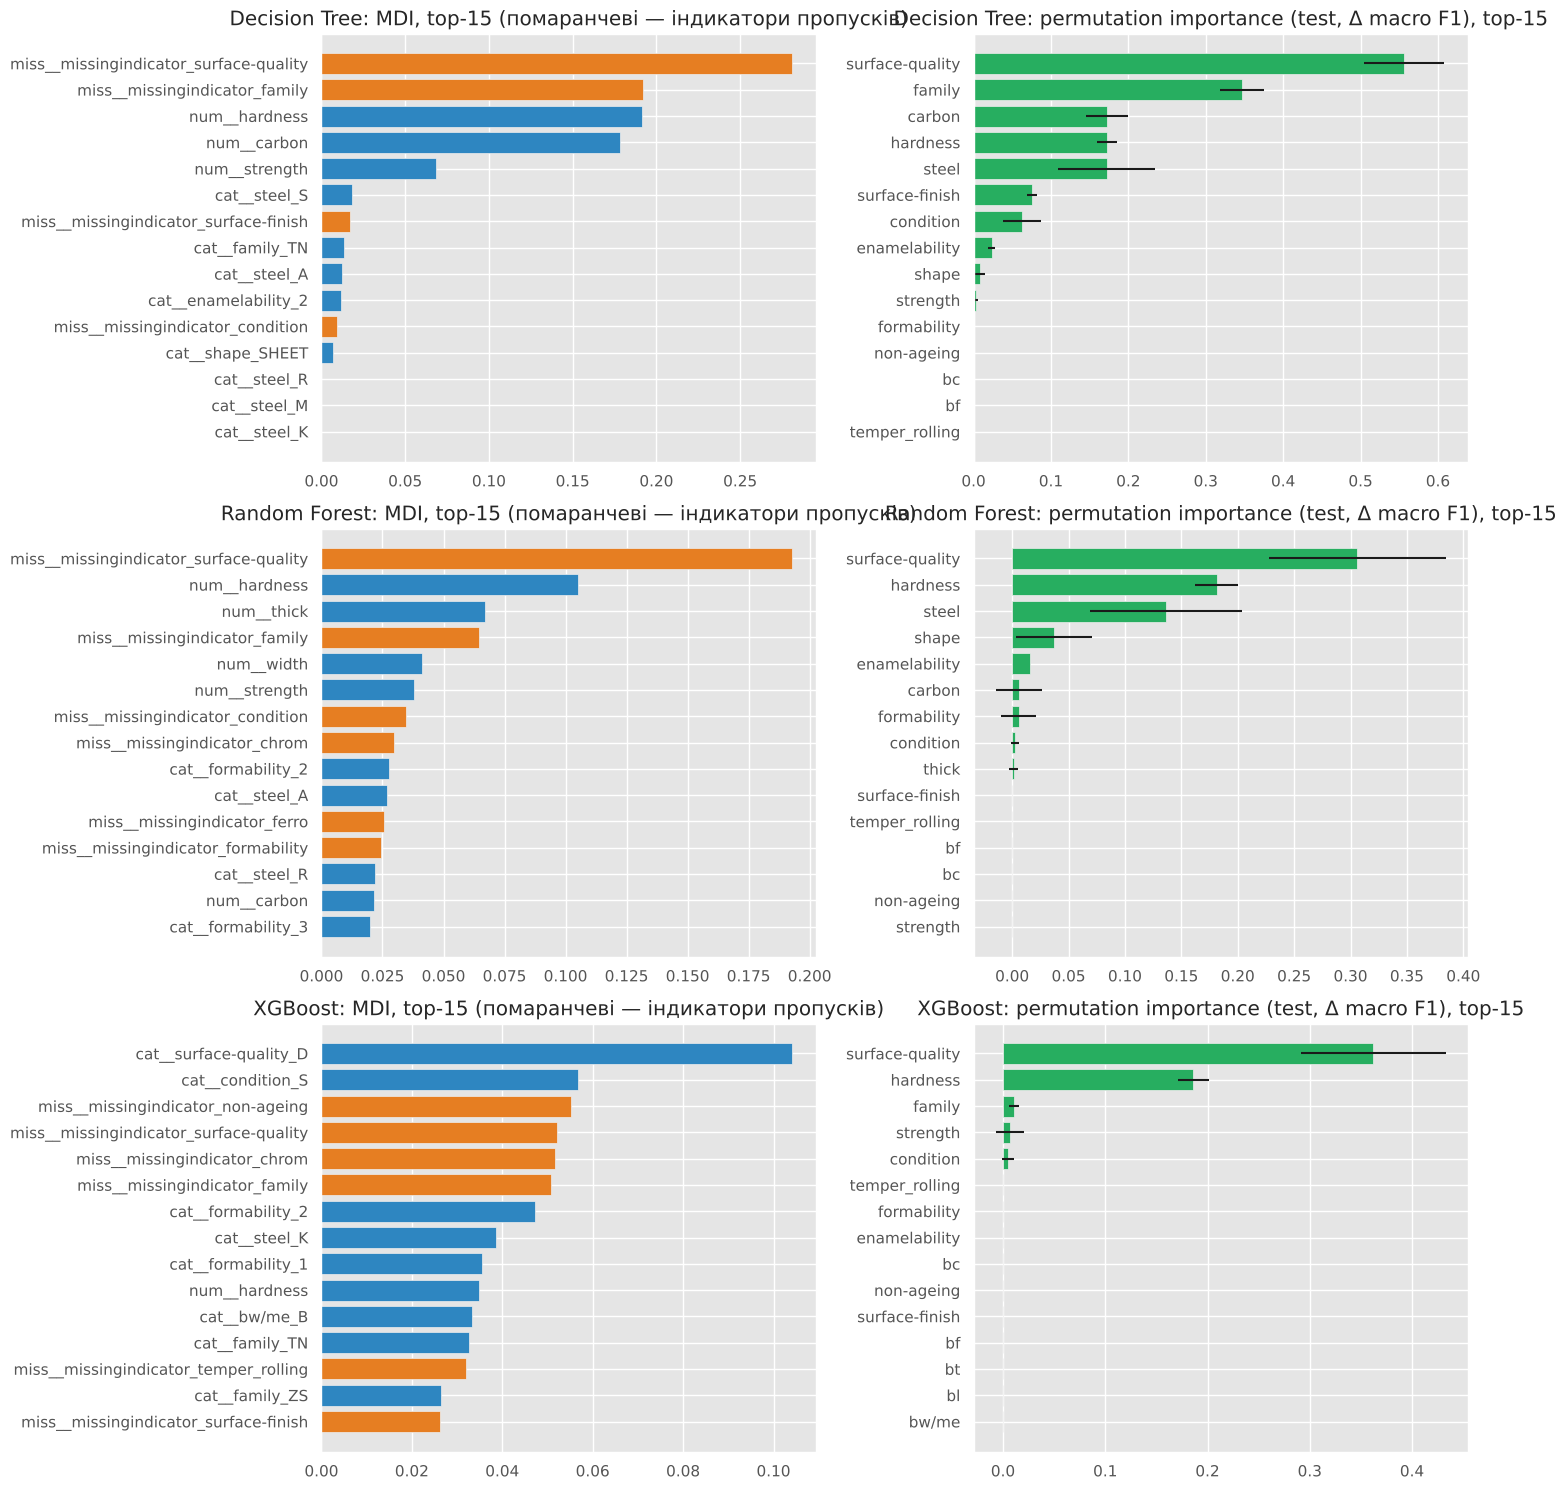

In [26]:
mdi, perm = {}, {}
for m in MODELS:
    names = final_models[m].named_steps['prep'].get_feature_names_out()
    mdi[m] = pd.Series(final_models[m].named_steps['clf'].feature_importances_, index=names).sort_values(ascending=False)
    pi = permutation_importance(final_models[m], X_test, y_test, scoring='f1_macro',
                                n_repeats=20, random_state=SEED, n_jobs=1)
    perm[m] = pd.DataFrame({'mean': pi.importances_mean, 'std': pi.importances_std},
                           index=X_test.columns).sort_values('mean', ascending=False)

fig, axes = plt.subplots(len(MODELS), 2, figsize=(15, 5 * len(MODELS)))
for i, m in enumerate(MODELS):
    top = mdi[m].head(15)[::-1]
    colors = ['#e67e22' if n.startswith('miss__') else '#2e86c1' for n in top.index]
    axes[i, 0].barh(top.index, top.values, color=colors)
    axes[i, 0].set_title(f'{MODEL_NAMES[m]}: MDI, top-15 (помаранчеві — індикатори пропусків)')
    tp = perm[m].head(15)[::-1]
    axes[i, 1].barh(tp.index, tp['mean'], xerr=tp['std'], color='#27ae60')
    axes[i, 1].set_title(f'{MODEL_NAMES[m]}: permutation importance (test, Δ macro F1), top-15')
plt.tight_layout(); plt.show()

In [27]:
# Чи є індикатори пропусків у top-15 MDI?
for m in MODELS:
    ind = [(n, round(v, 4)) for n, v in mdi[m].head(15).items() if n.startswith('miss__')]
    share = mdi[m][[n for n in mdi[m].index if n.startswith('miss__')]].sum()
    print(f'{MODEL_NAMES[m]:14s} індикаторів у top-15: {len(ind)}; сумарна MDI усіх індикаторів = {share:.3f}')
    for n, v in ind: print('    ', n, v)

Decision Tree  індикаторів у top-15: 4; сумарна MDI усіх індикаторів = 0.499
     miss__missingindicator_surface-quality 0.2812
     miss__missingindicator_family 0.1918
     miss__missingindicator_surface-finish 0.0171
     miss__missingindicator_condition 0.0094
Random Forest  індикаторів у top-15: 6; сумарна MDI усіх індикаторів = 0.473
     miss__missingindicator_surface-quality 0.1929
     miss__missingindicator_family 0.0647
     miss__missingindicator_condition 0.0346
     miss__missingindicator_chrom 0.0297
     miss__missingindicator_ferro 0.0258
     miss__missingindicator_formability 0.0244
XGBoost        індикаторів у top-15: 6; сумарна MDI усіх індикаторів = 0.396
     miss__missingindicator_non-ageing 0.0552
     miss__missingindicator_surface-quality 0.0521
     miss__missingindicator_chrom 0.0516
     miss__missingindicator_family 0.0508
     miss__missingindicator_temper_rolling 0.0319
     miss__missingindicator_surface-finish 0.0261


In [28]:
# Узгодженість MDI і permutation importance: агрегуємо MDI до початкових ознак
def mdi_by_original(m):
    s = mdi[m].copy()
    orig = []
    for n in s.index:
        block, rest = n.split('__', 1)
        if block == 'num':
            orig.append(rest)
        elif block == 'miss':
            orig.append(rest.replace('missingindicator_', ''))
        else:  # cat: <ознака>_<значення>
            orig.append(next(c for c in sorted(X.columns, key=len, reverse=True) if rest.startswith(c + '_')))
    return s.groupby(orig).sum()

agree = []
for m in MODELS:
    a = mdi_by_original(m).reindex(X.columns).fillna(0)
    b = perm[m]['mean'].reindex(X.columns)
    rho = stats.spearmanr(a, b).statistic
    top_a, top_b = set(a.nlargest(10).index), set(b.nlargest(10).index)
    agree.append({'модель': MODEL_NAMES[m], 'Spearman ρ (MDI агрег. vs perm.)': round(rho, 3),
                  'спільних у top-10': len(top_a & top_b),
                  'top-5 MDI (агрег.)': ', '.join(a.nlargest(5).index),
                  'top-5 permutation': ', '.join(b.nlargest(5).index)})
pd.DataFrame(agree)

,модель,Spearman ρ (MDI агрег. vs perm.),спільних у top-10,top-5 MDI (агрег.),top-5 permutation
0,Decision Tree,0.990,10,"surface-quality, family, hardness, carbon, str...","surface-quality, family, carbon, hardness, steel"
1,Random Forest,0.504,6,"surface-quality, hardness, steel, family, form...","surface-quality, hardness, steel, shape, ename..."
2,XGBoost,0.259,7,"surface-quality, steel, formability, family, c...","surface-quality, hardness, family, strength, c..."


**Відповіді на запитання.**

*Чи потрапили індикатори пропусків до top-15 MDI?* Так, і на перші позиції: у DT 4 індикатори в top-15, причому `missingindicator_surface-quality` (0,281) і `missingindicator_family` (0,192) — дві найважливіші ознаки всієї моделі; у RF і XGB — по 6 індикаторів у top-15. Сумарна MDI усіх індикаторів становить ≈0,50 (DT), 0,47 (RF) і 0,40 (XGB) — приблизно половина всієї «важливості». Це повністю узгоджується з п. 3.1: саме `surface-quality` і `family` мали найсильніший зв’язок «пропуск ↔ клас» (V Крамера 0,74 і 0,72). Модель використовує сам факт пропуску як ознаку — що можливо лише тоді, коли пропуски не MCAR.

*Наскільки узгоджуються MDI і permutation importance?* Для порівняння MDI агреговано до початкових ознак (сума по one-hot-стовпцях та індикатору). Для DT узгодженість майже повна (ρ Спірмена = 0,99, 10 із 10 спільних у top-10), для RF — помірна (ρ = 0,50, 6 спільних), для XGB — слабка (ρ = 0,26, 7 спільних). В усіх моделях першою за permutation importance є `surface-quality`. MDI обчислюється на навчальних даних і зміщена на користь ознак із великою кількістю унікальних значень [10]: числові `thick` (50 унікальних значень) і `width` (68) мають багато можливих порогів, тому в глибоких вузлах «випадково» дають невелике зменшення неоднорідності й набирають MDI: у RF це 0,067 і 0,041 (`width` — 5-те місце серед усіх оброблених ознак), а їхня permutation importance на тесті ≈0 (0,001 і 0,000). Ще одна причина розбіжності — корельовані ознаки: `family` у RF має високу MDI (разом з індикатором), але майже нульову permutation importance, бо її інформацію дублюють `surface-quality` та інші ознаки, і після перемішування `family` модель обходиться без неї. Для XGBoost `feature_importances_` — це середній gain, а не MDI у класичному сенсі, і він ще сильніше залежить від того, у яких деревах (раніх чи пізніх) використана ознака.

*Чому важливості однієї ознаки відрізняються між DT, RF і XGB?* Одне дерево жадібно обирає найкраще розбиття, і серед корельованих ознак (наприклад, `surface-quality` та її індикатор, `family` та індикатор) «забирає» всю важливість одна. RF через `max_features` змушений будувати дерева на різних підмножинах ознак, тож важливість розподіляється між взаємозамінними ознаками. XGBoost будує дерева послідовно: перші дерева використовують найсильніші ознаки, а пізніші — ті, що виправляють залишки на складних об’єктах рідкісних класів (`steel`, `formability`, `condition`), тому важливість зміщується в бік ознак, корисних саме для них.

## 3.8. Аналіз розбіжностей між моделями
Об’єкт розбіжності — якщо прогнози трьох фінальних моделей не всі однакові.

In [29]:
P = pd.DataFrame({'Справжній клас': le.inverse_transform(y_test)}, index=X_test.index)
for m in MODELS:
    P[MODEL_NAMES[m]] = le.inverse_transform(test_pred[m])
disagree_test = P[P[[MODEL_NAMES[m] for m in MODELS]].nunique(axis=1) > 1].copy()
disagree_test['Джерело'] = 'test'
print('Об’єктів розбіжності в тестовій вибірці:', len(disagree_test))

tables = [disagree_test]
if len(disagree_test) < 3:
    # доповнюємо out-of-fold прогнозами на train (моделі не бачили ці об'єкти під час навчання)
    oof_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    Po = pd.DataFrame({'Справжній клас': le.inverse_transform(y_train)}, index=X_train.index)
    for m in MODELS:
        oof = cross_val_predict(build_pipeline(m, True, studies[m].best_params), X_train, y_train, cv=oof_cv)
        Po[MODEL_NAMES[m]] = le.inverse_transform(oof)
    disagree_oof = Po[Po[[MODEL_NAMES[m] for m in MODELS]].nunique(axis=1) > 1].copy()
    disagree_oof['Джерело'] = 'train, out-of-fold (cross_val_predict)'
    print('Доповнено OOF-об’єктами з train:', len(disagree_oof))
    tables.append(disagree_oof)
t7 = pd.concat(tables)
t7.index = [f'#{i}' for i in t7.index]
t7.index.name = 'Об’єкт (індекс у датасеті)'
t7

Об’єктів розбіжності в тестовій вибірці: 3


,Справжній клас,Decision Tree,Random Forest,XGBoost,Джерело
Об’єкт (індекс у датасеті),,,,,
#90,U,U,3,3,test
#406,1,1,1,3,test
#827,3,3,2,2,test


**Таблиця 7** — об’єкти розбіжностей (номер = індекс рядка в початковому датасеті).

### Детальний аналіз одного об’єкта розбіжності

In [30]:
# Обираємо тестовий об'єкт розбіжності, де моделі найменш упевнені (найменша різниця ймовірностей)
proba = {m: pd.DataFrame(final_models[m].predict_proba(X_test), index=X_test.index, columns=CLASS_NAMES)
         for m in MODELS}
cand = disagree_test.index if len(disagree_test) else X_test.index
def margin(idx):
    return np.mean([np.sort(proba[m].loc[idx].values)[-1] - np.sort(proba[m].loc[idx].values)[-2] for m in MODELS])
OBJ = min(cand, key=margin)
x_raw = X_test.loc[[OBJ]]
print(f'Об’єкт #{OBJ}; справжній клас = {P.loc[OBJ, "Справжній клас"]}')
print({MODEL_NAMES[m]: P.loc[OBJ, MODEL_NAMES[m]] for m in MODELS})

# Ймовірності predict_proba
pd.concat({MODEL_NAMES[m]: proba[m].loc[OBJ] for m in MODELS}, axis=1).T.round(3)

Об’єкт #406; справжній клас = 1
{'Decision Tree': '1', 'Random Forest': '1', 'XGBoost': '3'}


,1,2,3,5,U
Decision Tree,1.000,0.000,0.000,0.000,0.000
Random Forest,0.604,0.161,0.231,0.000,0.004
XGBoost,0.323,0.113,0.550,0.008,0.006


In [31]:
# Початкові значення ознак, пропуски та значення, якими їх заповнено
prep = final_models[BEST].named_steps['prep']
fill = {}
for name, trans, cols in prep.transformers_:
    if name == 'num':
        fill.update(dict(zip(cols, trans.statistics_)))
    elif name == 'cat':
        fill.update(dict(zip(cols, trans.named_steps['impute'].statistics_)))
obj_tbl = pd.DataFrame({'початкове значення': x_raw.iloc[0].astype(object).where(x_raw.iloc[0].notna(), '— (NaN)'),
                        'пропущено': x_raw.iloc[0].isna().map({True: 'так', False: ''}),
                        'після імпутації': [fill[c] if pd.isna(v) else v for c, v in x_raw.iloc[0].items()]})
print('Пропущено ознак:', int(x_raw.iloc[0].isna().sum()), 'з', X.shape[1])
obj_tbl

Пропущено ознак: 22 з 31


,початкове значення,пропущено,після імпутації
family,— (NaN),так,TN
steel,S,,S
carbon,0.0,,0.0
hardness,0.0,,0.0
temper_rolling,— (NaN),так,T
condition,— (NaN),так,S
formability,— (NaN),так,2
strength,700.0,,700.0
non-ageing,— (NaN),так,N
surface-finish,— (NaN),так,P


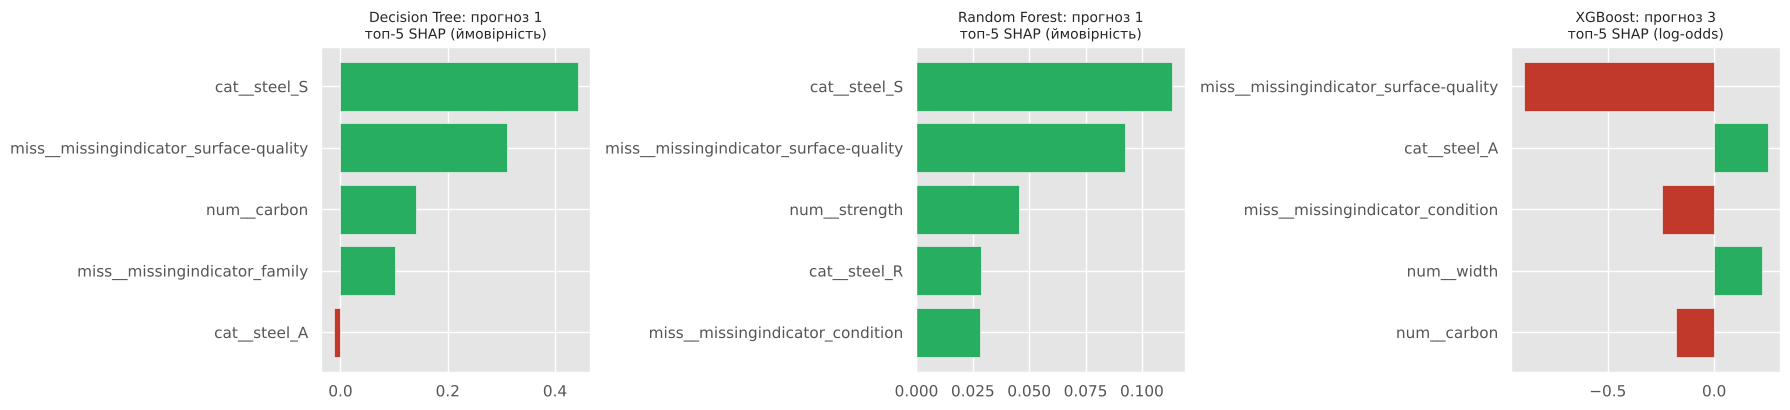

=== Decision Tree
                                        значення після обробки    SHAP
cat__steel_S                                               1.0  0.4425
miss__missingindicator_surface-quality                     1.0  0.3096
num__carbon                                                0.0  0.1400
miss__missingindicator_family                              1.0  0.1019
cat__steel_A                                               0.0 -0.0127 

=== Random Forest
                                        значення після обробки    SHAP
cat__steel_S                                               1.0  0.1134
miss__missingindicator_surface-quality                     1.0  0.0923
num__strength                                            700.0  0.0453
cat__steel_R                                               0.0  0.0287
miss__missingindicator_condition                           1.0  0.0284 

=== XGBoost
                                        значення після обробки    SHAP
miss__missingindicator_su

In [32]:
# SHAP: внески ознак у прогнозований клас для кожної моделі
def shap_for(m, x):
    prep_m, clf = final_models[m].named_steps['prep'], final_models[m].named_steps['clf']
    xt = pd.DataFrame(prep_m.transform(x), columns=prep_m.get_feature_names_out(), index=x.index)
    expl = shap.TreeExplainer(clf)
    sv = expl.shap_values(xt)
    if isinstance(sv, list):                 # старі версії shap: список по класах
        sv = np.stack(sv, axis=-1)
    sv = np.asarray(sv)                      # (n_samples, n_features, n_classes)
    return xt, sv

shap_top = {}
fig, axes = plt.subplots(1, len(MODELS), figsize=(18, 4.2))
for ax, m in zip(axes, MODELS):
    xt, sv = shap_for(m, x_raw)
    k = int(final_models[m].predict(x_raw)[0])
    contrib = pd.Series(sv[0, :, k], index=xt.columns)
    top = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(5)
    shap_top[m] = pd.DataFrame({'значення після обробки': xt.iloc[0][top.index], 'SHAP': top})
    ax.barh(top.index[::-1], top.values[::-1], color=['#c0392b' if v < 0 else '#27ae60' for v in top.values[::-1]])
    unit = 'log-odds' if m == 'XGB' else 'ймовірність'
    ax.set_title(f'{MODEL_NAMES[m]}: прогноз {CLASS_NAMES[k]}\nтоп-5 SHAP ({unit})', fontsize=10)
plt.tight_layout(); plt.show()

for m in MODELS:
    print(f'=== {MODEL_NAMES[m]}'); print(shap_top[m].round(4).to_string(), '\n')

In [33]:
# Як «бачать» цей об'єкт інші об'єкти навчальної вибірки: найближчі сусіди за обробленими ознаками
from sklearn.neighbors import NearestNeighbors
prep_b = final_models[BEST].named_steps['prep']
Xt_tr = prep_b.transform(X_train); xt_obj = prep_b.transform(x_raw)
nn = NearestNeighbors(n_neighbors=10).fit(Xt_tr)
dist, idx = nn.kneighbors(xt_obj)
print('Класи 10 найближчих сусідів у train:', list(le.inverse_transform(y_train[idx[0]])))

Класи 10 найближчих сусідів у train: ['3', '3', '3', '1', '3', '3', '3', '2', '3', '3']


**Аналіз об’єкта #406.** Через ефект стелі розбіжностей у тесті лише 3 (#90, #406, #827) — мінімально достатньо, OOF-доповнення не знадобилося. Показово, що дерево рішень в усіх трьох випадках дало правильний прогноз, а ансамблі зсувалися до сусіднього класу (#90: `U → 3` у RF і XGB; #827: `3 → 2` у RF і XGB; #406: `1 → 3` лише у XGB).

Для детального аналізу взято об’єкт #406 (справжній клас `1` — найрідкісніший). У нього пропущено 22 з 31 ознак, і після імпутації він виглядає як «типовий» об’єкт: `family = TN`, `surface-quality = E`, `formability = 2` тощо — це моди тренувальної вибірки, тобто значення, характерні для класів `2`/`3`. Розрізнити об’єкт можуть лише спостережувані `steel = S`, `strength = 700` і самі індикатори пропусків.

- **Decision Tree** (P(1) = 1,00): прогноз визначають `steel_S` (+0,44) та індикатор пропуску `surface-quality` (+0,31). Дерево має «жорсткий» поріг: об’єкт потрапляє в чистий лист, де лежать лише об’єкти класу `1`, тому впевненість 100 %.
- **Random Forest** (P(1) = 0,60, P(3) = 0,23): ті самі дві головні ознаки (`steel_S`, індикатор `surface-quality`), але їхні внески менші, бо частина дерев не бачила `steel` у потрібних вузлах (`max_features = sqrt`) — усереднення «розмиває» впевненість, хоча клас `1` ще перемагає.
- **XGBoost** (P(3) = 0,55, P(1) = 0,32): для прогнозованого класу `3` найбільший внесок має той самий індикатор `surface-quality`, але **від’ємний** (−0,90 log-odds) — тобто він «тягне» від класу `3`. Проте базове значення класу `3` (апріорі 76 % вибірки) і позитивні внески `steel_A = 0`, `width = 609.9` переважили. Бустинг зі зменшеним кроком (`learning_rate` ≈ 0,04) і обмеженням `min_child_weight` не може виділити окремий лист для кількох об’єктів класу `1`: у багатокласовій задачі гессіан p(1−p) для рідкісного класу малий, і сума гессіанів у листку з 4–6 такими об’єктами може не досягати порогу.

Об’єкт лежить близько до межі класів: з 10 найближчих сусідів у train 8 належать до класу `3` і лише 1 — до класу `1`. Тому розбіжність пояснюється поєднанням трьох чинників: (1) імпутовані значення роблять об’єкт схожим на домінуючий клас, (2) індикатори пропусків і `steel` — єдиний сигнал на користь класу `1`, (3) одне дерево використовує цей сигнал «жорстко» й угадує, а ансамблі через усереднення/регуляризацію схиляються до класу більшості. На цих трьох прикладах DT виграв, але на вкладеній CV у середньому ансамблі стабільніші.

## Висновки

1. За неупередженою оцінкою вкладеної крос-валідації найкращий macro F1 має **XGBoost** (0,951 ± 0,086), далі Random Forest (0,922 ± 0,091) і Decision Tree (0,908 ± 0,092); за CV 5×3 з типовими параметрами лідирує RF (0,967 ± 0,053), але різниця RF − XGB (0,004, p = 0,365) статистично незначуща, а стандартні відхилення на порядок більші за різниці між моделями — однозначного лідера немає, і результат нестабільний через клас `1` із 8 об’єктів.
2. Індикатори пропусків дали найсильніший ефект у роботі: +0,045…+0,081 macro F1 і +0,034…+0,040 accuracy для всіх трьох моделей (значуще за тестом Наде–Бенжіо для RF, p = 0,001; для DT і XGB p = 0,064 і 0,095 — той самий напрям, але більший розкид).
3. Це узгоджується з аналізом механізму пропусків (для 21 з 23 ознак пропуск пов’язаний із класом, тобто не MCAR) і з важливостями: індикатори `surface-quality` та `family` — найважливіші ознаки DT за MDI, а сума MDI усіх індикаторів становить 0,40–0,50.
4. `best_value` перевищує nested-оцінку на 0,038 (DT) і 0,042 (RF), тож звітування `best_value` переоцінило б модель приблизно на 4 п.п.; для XGBoost різниця −0,011 лежить у межах шуму.
5. Оптимізація майже нічого не дала: порівняно з типовими параметрами на тих самих блоках найбільший (і мізерний) приріст отримав лише XGBoost (+0,003), а DT і RF після налаштування навіть погіршилися (≈ −0,03), бо типові параметри вже дозволяють виділяти рідкісні класи, а внутрішня CV з 2–3 об’єктами класу `1` дає шумну цільову функцію.
6. Найскладніші класи — `1` (8 об’єктів; XGBoost на тесті розпізнав 1 з 2) і `U` (помилки `U → 3`), а також пара `2`/`3`: рідкісних прикладів мало, а після імпутації модами вони стають схожими на домінуючий клас `3`.
7. Об’єктів розбіжності в тесті лише 3 (ефект стелі); в усіх дерево рішень було правильним, а SHAP показав, що вирішальні ознаки — індикатор пропуску `surface-quality` і `steel`, а розбіжність виникає через «жорсткий» поріг DT проти усереднення й регуляризації ансамблів для об’єкта, що лежить біля межі з класом `3`.
8. Для практичного використання я обрала б **Random Forest з індикаторами пропусків**: його якість статистично не гірша за XGBoost, результат добре підтвердився на тесті (macro F1 0,980), він найменш чутливий до гіперпараметрів (типові вже близькі до оптимальних) і дешевший у налаштуванні; XGBoost — рівноцінна альтернатива з трохи вищою nested-оцінкою, а одне дерево варто залишити лише як найбільш інтерпретовну, але найменш стабільну модель.

## Відповіді на контрольні питання

**1. RF vs окреме дерево (зміщення/дисперсія).** Глибоке дерево має мале зміщення, але велику дисперсію: невелика зміна навчальних даних змінює структуру розбиттів. Випадковий ліс усереднює B дерев, навчених на бутстреп-вибірках, тому зміщення лишається приблизно як в одного дерева, а дисперсія зменшується. Дисперсія середнього корельованих дерев дорівнює ρσ² + (1−ρ)σ²/B: при B → ∞ залишається доданок ρσ², тому ключовою є **декореляція** дерев — випадковий вибір підмножини ознак (`max_features`) у кожному вузлі зменшує ρ.

**2. Бустинг vs беггінг.** Беггінг будує моделі незалежно й паралельно на бутстреп-вибірках і усереднює їх — зменшує дисперсію; збільшення кількості дерев практично не призводить до перенавчання. Бустинг будує дерева послідовно, кожне наступне апроксимує антиградієнт функції втрат (залишки) попереднього ансамблю — зменшує насамперед зміщення. Саме бустинг схильніший до перенавчання з ростом кількості дерев, бо кожне нове дерево все точніше підганяється під залишки навчальної вибірки, включно з шумом; проти цього діють learning rate, subsample, обмеження глибини, регуляризація та рання зупинка.

**3. Macro F1 / balanced accuracy.** За сильного дисбалансу accuracy визначається домінуючим класом: модель, що завжди прогнозує клас 3, на Annealing мала б accuracy ≈ 0,76. Balanced accuracy — середній recall по класах, macro F1 — середнє F1 по класах, тому кожен клас, навіть із 8 об’єктів, має однакову вагу. Macro-усереднення — просте середнє F1 класів; weighted — середнє з вагами, пропорційними підтримці класу, тому воно знову наближається до accuracy й «приховує» погану якість на рідкісних класах.

**4. MCAR, MAR, MNAR.** MCAR — пропуск не залежить ні від яких даних; MAR — залежить лише від спостережуваних ознак; MNAR — залежить від самого відсутнього значення або неспостережуваних чинників. Індикатори пропусків найкорисніші, коли пропуск інформативний щодо цілі (MAR, пов’язаний із класом, і особливо MNAR та структурні пропуски); за MCAR вони не дають додаткової інформації. Відрізнити MAR від MNAR лише за спостережуваними даними однозначно неможливо, бо для перевірки потрібні саме ті значення, яких немає; це можна обґрунтувати лише знанням предметної області або додатковими даними.

**5. Витік даних.** (а) Імпутація/кодування/масштабування з `fit` на всьому датасеті до поділу або до CV — статистики (медіана, мода, набір категорій) містять інформацію з валідаційних і тестових об’єктів; (б) передача в Optuna вже оброблених даних — ефект той самий всередині внутрішньої CV; (в) використання тестової вибірки в цільовій функції або для вибору моделі; (г) звітування `best_value` як якості. Запобігання: уся обробка — всередині `Pipeline`, який передається в `cross_val_score`/`tune`; тест використовується один раз; якість після оптимізації оцінюється вкладеною CV.

**6. Чому `best_value` оптимістичний; вкладена CV.** `best_value` — максимум із багатьох зашумлених оцінок CV; оскільки ми обираємо найбільшу, вона систематично завищена (у ній «вибрано» сприятливий шум конкретних блоків — selection bias). У вкладеній CV зовнішній цикл ділить дані на train/val, внутрішній цикл на кожному зовнішньому train виконує весь підбір гіперпараметрів, після чого модель з найкращими параметрами оцінюється на зовнішньому val, який у підборі не брав участі. Насправді оцінюється не одна конкретна модель, а **вся процедура навчання** «пайплайн + Optuna-пошук» — тобто очікувана якість моделі, отриманої цим методом на даних такого розміру.

**7. Тест Наде–Бенжіо.** Блоки CV мають перетинні тренувальні множини, тому різниці метрик на блоках корельовані; звичайний парний t-тест вважає їх незалежними, недооцінює дисперсію (знаменник 1/(kr)) і дає занадто багато хибно значущих результатів. Поправка Наде–Бенжіо додає до множника доданок n_test/n_train, який враховує цю кореляцію і збільшує оцінку дисперсії. У цій роботі це добре видно: звичайний t-тест показує значущість там, де скоригований — ні.

**8. MDI vs permutation importance.** MDI — сума зменшень неоднорідності (Gini/ентропії) по всіх вузлах, де використана ознака, обчислюється на навчальних даних; вона зміщена на користь неперервних ознак і ознак із багатьма унікальними значеннями (більше можливих порогів — більше шансів «випадково» зменшити неоднорідність) і не відображає узагальнення. Permutation importance — падіння метрики на відкладених даних після випадкового перемішування ознаки; вона модель-агностична й прямо вимірює вплив на якість. Корельовані ознаки: у MDI важливість «розділяється» між ними (довільно, залежно від того, яку обрало дерево); у permutation importance обидві можуть отримати занижену важливість, бо модель використовує інформацію корельованої «напарниці», а перемішування створює ще й нереалістичні комбінації значень.

**9. SHAP.** SHAP-значення — значення Шеплі з кооперативної теорії ігор: внесок ознаки дорівнює її середньому граничному внеску в прогноз по всіх можливих коаліціях ознак. Властивість адитивності (local accuracy): прогноз = базове значення E[f(x)] + сума SHAP-значень усіх ознак для цього об’єкта. Локальне пояснення показує, чому модель зробила конкретний прогноз для одного об’єкта; глобальна важливість описує середній вплив ознаки на всій вибірці (наприклад, середнє |SHAP| або permutation importance) і може не збігатися з тим, що визначає окремий прогноз.

**10. Нативна обробка пропусків у XGBoost (sparsity-aware split finding).** Для кожного вузла під час пошуку розбиття алгоритм перебирає пороги лише за непропущеними значеннями, а об’єкти з пропуском пробно відправляє спочатку всі вліво, потім усі вправо, і запам’ятовує **напрямок за замовчуванням** (default direction), що дає більший приріст функції втрат. На етапі прогнозу об’єкт із пропуском у цій ознаці йде гілкою за замовчуванням. Так модель сама «вивчає», куди краще віднести відсутні значення, а обчислювальна складність пропорційна кількості непропущених значень.

**11. Переваги Optuna.** TPE-семплер — байєсівська оптимізація: будує дві густини (для «хороших» і «поганих» спроб) і пропонує точки з великим відношенням l(x)/g(x), тобто використовує результати попередніх спроб, а не перебирає сітку наосліп; тому досягає хорошого результату за меншу кількість спроб, ніж GridSearchCV (експоненційна кількість комбінацій) і RandomizedSearchCV (незалежні випадкові точки). Прунінг зупиняє безперспективні спроби на ранніх етапах (наприклад, після перших блоків CV чи ітерацій бустингу). Також: define-by-run простір пошуку (умовні гіперпараметри), логарифмічні шкали, візуалізація історії та важливості параметрів, збереження/продовження досліджень.